# 09 · Hybrid model: char-CNN + handcrafted URL features (Milestone 5)

The two kinds of URL model see different things:
- **Char-CNN** (notebook 08): learned character patterns (`paypa1`, `.top`, random strings).
- **Our 40 features** (notebook 03, `extract_features`): counts and structure (number of subdomains, IP address, entropy, hosting platform …).

We try two standard ways to combine them:

| Approach | How | Name in ML |
|---|---|---|
| **Hybrid network** | The CNN's 512 pattern scores and the 40 features (log-scaled, standardised) are concatenated **inside one network** and trained together. | early / joint fusion |
| **Log-odds average** | A CNN and an XGBoost (on the features) are trained **separately**, then their log-odds are averaged. | late fusion |

Same protocol as always: 3 views (raw URL, domain only, registered domain), 5 splits, McNemar tests. The question: **does combining beat the best single model (n-gram or CNN)?**

In [1]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer
import numpy as np
import pandas as pd
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.urls import URL_VIEWS
from phishguard.features import extract_features
from phishguard.deep import CharURLClassifier, HybridNet
from phishguard.ensemble import LogitAverage
from phishguard.evaluate import evaluate, load_results, precision_at_base_rate
from phishguard.experiment import run, summary_table, load_predictions, load_record, SEEDS
from phishguard.modeling import param_grid
from phishguard.stats import mcnemar

df = load_clean()
y = df[TARGET]
VIEWS = ["raw URL", "domain only", "registered domain"]

inputs = {}
for view in VIEWS:
    urls = URL_VIEWS[view](df["URL"])
    inputs[view] = extract_features(urls).assign(url=urls)      # 40 feature columns + the URL text
feature_cols = [c for c in inputs["raw URL"].columns if c != "url"]
inputs["domain only"].head(3)

,url_length,num_letters,num_digits,letter_ratio,digit_ratio,special_ratio,num_dots,num_hyphens,num_underscores,num_slashes,...,is_shortener,path_depth,num_query_params,has_fragment,double_slash_in_path,suspicious_words,longest_token,url_entropy,host_entropy,url
0,20,19,0,0.950000,0.0,0.050000,1,0,0,0,...,0,0,0,0,0,0,16,3.546439,3.546439,southbankmosaics.com
1,12,10,0,0.833333,0.0,0.166667,1,1,0,0,...,0,0,0,0,0,0,5,3.251629,3.251629,uni-mainz.de
2,18,16,0,0.888889,0.0,0.111111,2,0,0,0,...,0,0,0,0,0,0,12,3.572431,3.572431,voicefmradio.co.uk


## 1. The hybrid network

In [2]:
net = HybridNet(vocab_size=61, n_features=len(feature_cols))
print(f"{sum(p.numel() for p in net.parameters()):,} trainable weights")
net

152,801 trainable weights


HybridNet(
  (chars): CharCNN(
    (embed): Embedding(61, 32, padding_idx=0)
    (convs): ModuleList(
      (0): Conv1d(32, 128, kernel_size=(3,), stride=(1,))
      (1): Conv1d(32, 128, kernel_size=(4,), stride=(1,))
      (2): Conv1d(32, 128, kernel_size=(5,), stride=(1,))
      (3): Conv1d(32, 128, kernel_size=(6,), stride=(1,))
    )
    (head): Identity()
  )
  (features): Sequential(
    (0): Linear(in_features=40, out_features=64, bias=True)
    (1): ReLU()
  )
  (head): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=576, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)

- `chars`: the char-CNN from notebook 08, without its own output layer. It gives 4 widths × 128 filters = 512 pattern scores.
- `features`: the 40 handcrafted numbers → 64 numbers. Counts like `url_length` are very skewed, so they are first **log-scaled** (`log(1 + x)`) and **standardised** with the mean and sd of the training rows.
- `head`: 512 + 64 → 128 → 1 logit, with dropout.

Training is identical to notebook 08 (Adam, early stopping on held-out training owners, dropout ∈ {0.3, 0.5} tuned on validation).

## 2. The log-odds average
A char-CNN on the URL text and an XGBoost on the features, each trained on the training split, then averaged on the log-odds scale (`LogitAverage`, as in notebook 04). The CNN's dropout ∈ {0.3, 0.5} is tuned on validation. XGBoost uses `max_depth=6`, the setting it chose on every split and view in notebook 07.

## 3. Run both on 3 views × 5 splits (~1.5 hours)

In [3]:
make_hybrid = lambda dropout: CharURLClassifier(arch="hybrid", dropout=dropout)
make_xgb = lambda: XGBClassifier(max_depth=6, n_estimators=500, learning_rate=0.1, subsample=0.8,
                                 colsample_bytree=0.8, n_jobs=-1, random_state=42)
make_average = lambda dropout: LogitAverage({
    "cnn": (lambda: CharURLClassifier(arch="cnn", dropout=dropout), "url"),
    "xgb": (make_xgb, feature_cols),
})
grid = param_grid(dropout=[0.3, 0.5])

experiments = {}
for view in VIEWS:
    for model_name, make_model in {"Hybrid CNN + features": make_hybrid, "Average CNN + XGBoost": make_average}.items():
        exp = run(f"{model_name} | {view}", make_model, grid, inputs[view], y, df, features=view, group="m5_hybrid")
        experiments[(view, model_name)] = exp
        print(f"{model_name:22s} | {view:17s} {exp.summary.loc['accuracy', 'mean']:.2%} ± {exp.summary.loc['accuracy', 'sd']:.2%}")
summary_table(experiments.values())

Hybrid CNN + features  | raw URL           99.68% ± 0.03%


Average CNN + XGBoost  | raw URL           99.68% ± 0.03%


Hybrid CNN + features  | domain only       86.72% ± 0.99%


Average CNN + XGBoost  | domain only       85.70% ± 0.99%


Hybrid CNN + features  | registered domain 82.01% ± 0.85%


Average CNN + XGBoost  | registered domain 80.97% ± 1.80%


,accuracy (%),f1 (%),roc_auc,pr_auc,mcc,tpr_at_fpr_1pct (%),"accuracy, seed 42 [95% CI]"
model,,,,,,,
Hybrid CNN + features | raw URL,99.68 ± 0.03,99.62 ± 0.04,0.9983 ± 0.0002,0.9986 ± 0.0002,0.9935 ± 0.0007,99.48 ± 0.07,"99.74% [99.68%, 99.80%]"
Average CNN + XGBoost | raw URL,99.68 ± 0.03,99.62 ± 0.04,0.9981 ± 0.0003,0.9985 ± 0.0002,0.9935 ± 0.0006,99.46 ± 0.06,"99.73% [99.67%, 99.79%]"
Hybrid CNN + features | domain only,86.72 ± 0.99,82.22 ± 1.61,0.9173 ± 0.0055,0.9217 ± 0.0054,0.7354 ± 0.0191,66.33 ± 2.62,"88.05% [87.06%, 89.26%]"
Average CNN + XGBoost | domain only,85.70 ± 0.99,80.57 ± 1.71,0.9129 ± 0.0064,0.9174 ± 0.0064,0.7166 ± 0.0175,65.61 ± 2.48,"84.61% [79.38%, 87.79%]"
Hybrid CNN + features | registered domain,82.01 ± 0.85,76.08 ± 1.53,0.8853 ± 0.0064,0.8836 ± 0.0068,0.6334 ± 0.0176,50.09 ± 3.29,"83.39% [81.41%, 85.32%]"
Average CNN + XGBoost | registered domain,80.97 ± 1.80,73.34 ± 3.40,0.8770 ± 0.0104,0.8758 ± 0.0100,0.6184 ± 0.0323,49.17 ± 2.15,"78.88% [72.03%, 83.54%]"


## 4. Compared with the single models (same splits, same views)

In [4]:
FAMILIES = {"m3_views": ["Char n-gram LogReg", "XGBoost URL features"], "m4_deep": ["Char-CNN"],
            "m5_hybrid": ["Hybrid CNN + features", "Average CNN + XGBoost"]}
rows = []
for group, families in FAMILIES.items():
    for family in families:
        for view in VIEWS:
            record = load_record(group, f"{family} | {view}")
            rows.append({"family": family, "view": view, **{f"{m}": record["summary"][m]["mean"] for m in
                         ["accuracy", "roc_auc", "pr_auc", "mcc", "tpr_at_fpr_1pct"]},
                         "accuracy_sd": record["summary"]["accuracy"]["sd"]})
compare = pd.DataFrame(rows)
order = [f for fams in FAMILIES.values() for f in fams]
acc = compare.pivot(index="family", columns="view", values="accuracy").loc[order, VIEWS] * 100
sd = compare.pivot(index="family", columns="view", values="accuracy_sd").loc[order, VIEWS] * 100
acc.round(2).astype(str) + " ± " + sd.round(2).astype(str)

view,raw URL,domain only,registered domain
family,,,
Char n-gram LogReg,99.7 ± 0.03,86.27 ± 0.89,82.49 ± 1.93
XGBoost URL features,99.64 ± 0.03,81.43 ± 1.15,72.82 ± 0.7
Char-CNN,99.68 ± 0.03,86.58 ± 0.92,80.85 ± 1.53
Hybrid CNN + features,99.68 ± 0.03,86.72 ± 0.99,82.01 ± 0.85
Average CNN + XGBoost,99.68 ± 0.03,85.7 ± 0.99,80.97 ± 1.8


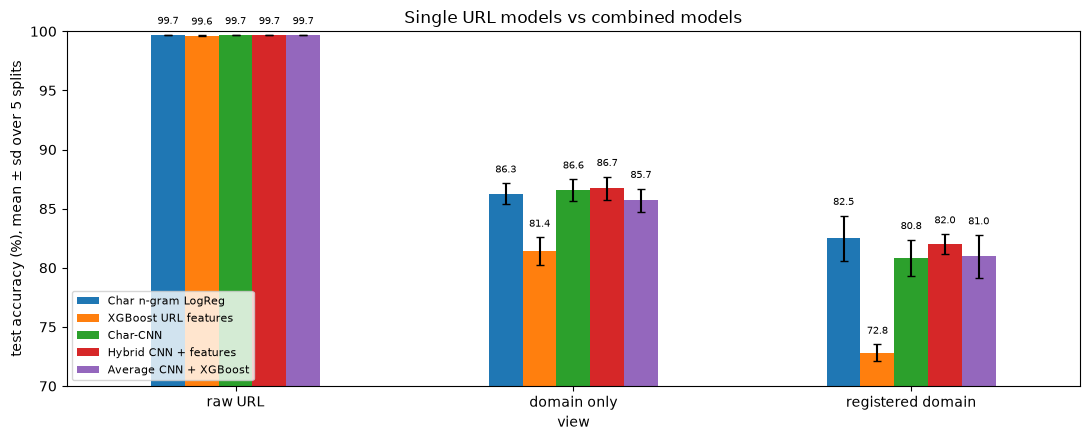

accuracy  roc_auc  pr_auc     mcc  \
view              family                                                     
raw URL           Char n-gram LogReg       0.9970   0.9985  0.9988  0.9938   
                  XGBoost URL features     0.9964   0.9972  0.9979  0.9927   
                  Char-CNN                 0.9968   0.9982  0.9985  0.9935   
                  Hybrid CNN + features    0.9968   0.9983  0.9986  0.9935   
                  Average CNN + XGBoost    0.9968   0.9981  0.9985  0.9935   
domain only       Char n-gram LogReg       0.8627   0.9162  0.9194  0.7233   
                  XGBoost URL features     0.8143   0.8473  0.8613  0.6296   
                  Char-CNN                 0.8658   0.9165  0.9205  0.7319   
                  Hybrid CNN + features    0.8672   0.9173  0.9217  0.7354   
                  Average CNN + XGBoost    0.8570   0.9129  0.9174  0.7166   
registered domain Char n-gram LogReg       0.8249   0.8945  0.8934  0.6490   
                  XGBoost URL features     0.7282   0.7698  0.7697  0.4644   
                  Char-CNN                 0.8085   0.8793  0.8753  0.6154   
                  Hybrid CNN + features    0.8201   0.8853  0.8836  0.6334   
                  Average CNN + XGBoost    0.8097   0.8770  0.8758  0.6184   

                                         tpr_at_fpr_1pct  
view              family                                  
raw URL           Char n-gram LogReg              0.9953  
                  XGBoost URL features            0.9935  
                  Char-CNN                        0.9946  
                  Hybrid CNN + features           0.9948  
                  Average CNN + XGBoost           0.9946  
domain only       Char n-gram LogReg              0.6385  
                  XGBoost URL features            0.5459  
                  Char-CNN                        0.6533  
                  Hybrid CNN + features           0.6633  
                  Average CNN + XGBoost           0.6561  
registered domain Char n-gram LogReg              0.5292  
                  XGBoost URL features            0.3434  
                  Char-CNN                        0.4720  
                  Hybrid CNN + features           0.5009  
                  Average CNN + XGBoost           0.4917

In [5]:
ax = acc.T.plot.bar(yerr=sd.T, capsize=3, figsize=(11, 4.5), rot=0)
ax.set_ylim(70, 100)
ax.set_ylabel("test accuracy (%), mean ± sd over 5 splits")
ax.set_title("Single URL models vs combined models")
for container in ax.containers:
    if isinstance(container, BarContainer):
        ax.bar_label(container, fmt="%.1f", fontsize=7, padding=6)
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()
compare.set_index(["view", "family"]).loc[VIEWS].drop(columns="accuracy_sd").round(4)

## 5. Is the combination really better?

Two checks, because notebook 08 showed that one split can mislead:
1. **Split by split:** the difference to the n-gram model and to the CNN on each of the 5 splits (accuracy in points, ROC-AUC).
2. **McNemar** on the seed-42 test set.

In [6]:
def per_seed(group, name):
    return {s["seed"]: s["test"] for s in load_record(group, name)["seeds"]}

BASELINES = {"n-gram": ("m3_views", "Char n-gram LogReg"), "CNN": ("m4_deep", "Char-CNN")}
rows = []
for view in VIEWS:
    for model_name in ["Hybrid CNN + features", "Average CNN + XGBoost"]:
        new = per_seed("m5_hybrid", f"{model_name} | {view}")
        new_pred = load_predictions("m5_hybrid", f"{model_name} | {view}")
        yt = y.loc[new_pred["test_idx"]].to_numpy()
        new_right = (new_pred["test_prob"] >= new_pred["threshold"]) == yt
        for base_name, (group, family) in BASELINES.items():
            base = per_seed(group, f"{family} | {view}")
            acc_diff = np.array([new[s]["accuracy"] - base[s]["accuracy"] for s in SEEDS]) * 100
            auc_diff = np.array([new[s]["roc_auc"] - base[s]["roc_auc"] for s in SEEDS])
            base_pred = load_predictions(group, f"{family} | {view}")
            assert (base_pred["test_idx"] == new_pred["test_idx"]).all()
            test = mcnemar(new_right, (base_pred["test_prob"] >= base_pred["threshold"]) == yt)
            rows.append({"view": view, "model": model_name, "vs": base_name,
                         "accuracy diff (points)": acc_diff.mean(), "splits better (accuracy)": f"{(acc_diff > 0).sum()}/5",
                         "ROC-AUC diff": auc_diff.mean(), "splits better (ROC-AUC)": f"{(auc_diff > 0).sum()}/5",
                         "seed 42: only new right": test["only_a_right"], "only baseline right": test["only_b_right"],
                         "p": test["p_value"]})
pd.DataFrame(rows).round({"accuracy diff (points)": 2, "ROC-AUC diff": 4, "p": 4})

,view,model,vs,accuracy diff (points),splits better (accuracy),ROC-AUC diff,splits better (ROC-AUC),seed 42: only new right,only baseline right,p
0,raw URL,Hybrid CNN + features,n-gram,-0.02,0/5,-0.0003,0/5,13,18,0.4731
1,raw URL,Hybrid CNN + features,CNN,-0.00,4/5,0.0001,3/5,10,6,0.4545
2,raw URL,Average CNN + XGBoost,n-gram,-0.01,1/5,-0.0004,0/5,14,21,0.3105
3,raw URL,Average CNN + XGBoost,CNN,0.00,4/5,-0.0001,1/5,17,15,0.8601
4,domain only,Hybrid CNN + features,n-gram,0.45,4/5,0.0011,3/5,1094,842,0.0000
5,domain only,Hybrid CNN + features,CNN,0.14,4/5,0.0008,4/5,612,536,0.0268
6,domain only,Average CNN + XGBoost,n-gram,-0.57,3/5,-0.0033,0/5,1139,2093,0.0000
7,domain only,Average CNN + XGBoost,CNN,-0.88,0/5,-0.0036,0/5,645,1775,0.0000
8,registered domain,Hybrid CNN + features,n-gram,-0.48,1/5,-0.0091,0/5,999,1573,0.0000
9,registered domain,Hybrid CNN + features,CNN,1.16,5/5,0.0060,4/5,856,766,0.0271


## 6. Does the hybrid actually use both inputs? (seed-42 test split)

**Permutation test:** shuffle one input across the test URLs, so it no longer matches its URL, and see how much the score drops. A big drop means the model relies on that input. No retraining is needed.

In [7]:
rows = []
for view in VIEWS:
    exp = experiments[(view, "Hybrid CNN + features")]
    model, threshold = exp.reference.model, exp.reference.threshold
    X_test = inputs[view].loc[exp.reference_splits[2]]
    yt = y.loc[X_test.index]
    shuffled = np.random.default_rng(0).permutation(len(X_test))
    variants = {
        "nothing shuffled": X_test,
        "features shuffled (only characters informative)": X_test.assign(**{c: X_test[c].to_numpy()[shuffled] for c in feature_cols}),
        "URL text shuffled (only features informative)": X_test.assign(url=X_test["url"].to_numpy()[shuffled]),
    }
    for name, X_variant in variants.items():
        m = evaluate(yt, model.predict_proba(X_variant)[:, 1], threshold)
        rows.append({"view": view, "input": name, "accuracy": m["accuracy"], "roc_auc": m["roc_auc"]})
pd.DataFrame(rows).pivot(index="input", columns="view", values=["accuracy", "roc_auc"]).round(4)

accuracy          \
view                                            domain only raw URL   
input                                                                 
URL text shuffled (only features informative)        0.6541  0.6393   
features shuffled (only characters informative)      0.7788  0.8688   
nothing shuffled                                     0.8805  0.9974   

                                                                      roc_auc  \
view                                            registered domain domain only   
input                                                                           
URL text shuffled (only features informative)              0.6006      0.6906   
features shuffled (only characters informative)            0.7758      0.8242   
nothing shuffled                                           0.8339      0.9243   

                                                                           
view                                            raw URL registered domain  
input                                                                      
URL text shuffled (only features informative)    0.7470            0.6038  
features shuffled (only characters informative)  0.9471            0.8281  
nothing shuffled                                 0.9984            0.8923

## 7. What the numbers mean in real traffic (mean over 5 splits)

In [8]:
rows = []
for (view, model_name), exp in experiments.items():
    recall = exp.per_seed["recall"].mean()
    fpr = (exp.per_seed["fp"] / (exp.per_seed["fp"] + exp.per_seed["tn"])).mean()
    rows.append({"view": view, "model": model_name, "recall": recall, "false-alarm rate": fpr,
                 **{f"precision at {p:.1%} phishing": precision_at_base_rate(recall, fpr, p) for p in [0.01, 0.001]}})
pd.DataFrame(rows).set_index(["view", "model"]).mul(100).round(2)

recall  false-alarm rate  \
view              model                                             
raw URL           Hybrid CNN + features   99.29              0.03   
                  Average CNN + XGBoost   99.30              0.03   
domain only       Hybrid CNN + features   72.68              2.99   
                  Average CNN + XGBoost   70.16              2.89   
registered domain Hybrid CNN + features   67.68              7.47   
                  Average CNN + XGBoost   62.17              5.22   

                                         precision at 1.0% phishing  \
view              model                                               
raw URL           Hybrid CNN + features                       96.94   
                  Average CNN + XGBoost                       96.76   
domain only       Hybrid CNN + features                       19.73   
                  Average CNN + XGBoost                       19.67   
registered domain Hybrid CNN + features                        8.38   
                  Average CNN + XGBoost                       10.73   

                                         precision at 0.1% phishing  
view              model                                              
raw URL           Hybrid CNN + features                       75.85  
                  Average CNN + XGBoost                       74.73  
domain only       Hybrid CNN + features                        2.38  
                  Average CNN + XGBoost                        2.37  
registered domain Hybrid CNN + features                        0.90  
                  Average CNN + XGBoost                        1.18

## What we learned
1. **Raw URL: still a tie.** Hybrid and average are both 99.68 ± 0.03%, the same as the CNN and the n-gram model (McNemar p ≥ 0.31). With the `https://www.` shortcut available, there is nothing left to gain.
2. **Domain only: the hybrid network is our best URL model, by a small margin.**
   - 86.72 ± 0.99% (ROC-AUC 0.9173), against n-gram 86.27% and CNN 86.58%.
   - vs the **n-gram model:** higher accuracy on 4/5 splits (+0.45 points); seed 42: 1,094 vs 842, p < 0.0001. ROC-AUC higher on 3/5 splits only (+0.001).
   - vs the **CNN alone:** higher accuracy on 4/5 splits and ROC-AUC on 4/5 (+0.14 points); seed 42: 612 vs 536, p = 0.027.
   - The gain is consistent in direction but smaller than the split-to-split sd (± 1 point). Honest wording: *"adding the handcrafted features to the CNN helps slightly and fairly consistently"*.
3. **Registered domain: the hybrid fixes most of the CNN's weakness, but the n-gram model still wins.**
   - Hybrid 82.01 ± 0.85%: better than the CNN on 5/5 splits (+1.16 points, p = 0.027).
   - Still below the n-gram model's 82.49% (ROC-AUC lower on 5/5 splits, p < 0.0001 on seed 42).
   - On these very short inputs, the regularised linear n-gram model remains hard to beat.
4. **Joint training beats averaging.** The log-odds average is *worse* than the CNN alone on domain only (0/5 splits, −0.88 points). Averaging gives XGBoost an equal vote although it is much weaker on domains (81.4%). The hybrid network instead **learns** how much to trust each input.
5. **The hybrid uses both inputs** (permutation test, seed 42):
   - On domain only, accuracy drops from 88.1% to 77.9% when the features are shuffled, and to 65.4% when the URL text is shuffled.
   - The characters carry more of the signal, but the features add information that the characters alone don't give.
6. **Real traffic:** at a 1% phishing rate, the domain-only hybrid would have ~20% precision. That is the best of our shortcut-reduced models, but still mostly false alarms on its own.
7. **For the next milestones:**
   - The **domain-only hybrid** is the model to explain (Milestone 6) and to attack (Milestone 7).
   - Its two branches let us explain it in two ways: SHAP on the 40 features, and character attributions on the URL text.
   - The **n-gram model** stays as the strong, simple baseline, and the best model on registered domains.